# A/B-тест новой формы оплаты ЖКХ
**Руслан Ахметов · продуктовая аналитика**

Задача: по результатам теста 1–30 апреля 2024 года решить, стоит ли внедрять
форму с упрощённым заполнением реквизитов. В условии явно не указано соответствие
вариантов: **принимаю A за старую форму, B за новую**.

Основная метрика — конверсия попыток: `успешные оплаты / открытия формы`.
Клиенты рандомизированы, а их попытки зависимы, поэтому расчёт неопределённости
проводится по клиентам. Пользовательская конверсия — отдельная дополнительная метрика.

В этом notebook находится весь код: загрузка, очистка, EDA, графики, таблицы,
статистические тесты, проверки устойчивости и формирование PDF. Графики и две
итоговые таблицы выводятся здесь как PNG; **те же изображения вставляются в PDF**.
Остальные подробные таблицы доступны ниже в стандартном выводе pandas.

## Как воспроизвести
Python 3.12. Установите зависимости из `requirements.txt`, откройте notebook в
Jupyter/VS Code и выполните **Restart Kernel → Run All**.
Положите исходный Excel в `data/` рядом с notebook или укажите `SOURCE_XLSX`
в следующей ячейке. Файл также ищется рядом с notebook и в Downloads.
В репозитории исходный Excel и сохранённая страница задания не публикуются.
Контрольная сумма источника и версии библиотек выводятся ниже.

Репозиторий: https://github.com/9ecolla/tbank-product-analytics-case

In [1]:
from pathlib import Path
import os
import sys
import json
import hashlib
import importlib.metadata as metadata
import platform
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager
import seaborn as sns
from IPython.display import display, Markdown

%matplotlib inline
SEED = 42
N_RESAMPLES = 20_000
ALPHA = 0.05
START = pd.Timestamp('2024-04-01')
END = pd.Timestamp('2024-05-01')  # правая граница не включается
FILE_NAME = 'dannye-dlia-keisa-po-pa-cebbefc3-5b29-4f88-b6d4-3336c88d743f.xlsx'
candidates = [Path('data') / FILE_NAME, Path(FILE_NAME), Path.home() / 'Downloads' / FILE_NAME]
SOURCE_XLSX = next((p.resolve() for p in candidates if p.is_file()), None)
if SOURCE_XLSX is None:
    raise FileNotFoundError('Укажите путь к исходному Excel в SOURCE_XLSX.')
OUTPUT_DIR = Path.cwd()
WORK_DIR = OUTPUT_DIR / '.artifacts'
WORK_DIR.mkdir(parents=True, exist_ok=True)
PDF_PATH = OUTPUT_DIR / 'report.pdf'
REPO_URL = 'https://github.com/9ecolla/tbank-product-analytics-case'
source_sha256 = hashlib.sha256(SOURCE_XLSX.read_bytes()).hexdigest()
STEPS = ['step1_opened', 'step2_entered', 'step3_confirmed', 'step4_success']
GROUPS = ['A', 'B']
COLORS = {'A': '#64748b', 'B': '#087e8b'}
sns.set_theme(style='whitegrid', font='DejaVu Sans', font_scale=0.95)
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False,
                     'axes.spines.right': False, 'savefig.bbox': 'tight'})
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', lambda x: f'{x:.4f}')

print('Python:', platform.python_version())
versions = {p: metadata.version(p) for p in
            ['pandas', 'numpy', 'scipy', 'matplotlib', 'seaborn', 'openpyxl', 'reportlab', 'pypdf', 'ipykernel', 'nbformat', 'nbclient']}
print('Версии:', versions)
print('SHA-256 исходного файла:', source_sha256)

Python: 3.12.14
Версии: {'pandas': '3.1.0', 'numpy': '2.5.4', 'scipy': '1.18.1', 'matplotlib': '3.11.2', 'seaborn': '0.13.2', 'openpyxl': '3.1.5', 'reportlab': '4.4.9', 'pypdf': '6.10.0', 'ipykernel': '7.4.0', 'nbformat': '5.11.1', 'nbclient': '0.11.0'}
SHA-256 исходного файла: f1e560b834c87e72a494f1413185104c817b3d6e4d4106afed1e5dfd1afb282b


## 1. Исходные данные и первичная проверка
Одна строка листа «Пользователи» — назначенный клиент; одна строка листа
«Платежи» — попытка оплаты. Отсутствующий последующий шаг — незавершение воронки,
а не автоматически ошибка данных. Дубликаты ключей блокируют расчёт, чтобы не
выбирать произвольную запись и не размножать строки при объединении.

In [2]:
raw_users = pd.read_excel(SOURCE_XLSX, sheet_name='Пользователи',
                          dtype={'user_id': 'Int64'})
raw_payments = pd.read_excel(SOURCE_XLSX, sheet_name='Платежи',
                             dtype={'user_id': 'Int64', 'payment_id': 'Int64'})
assert raw_users['user_id'].notna().all(), 'Пустой ключ в справочнике пользователей'
assert raw_users['user_id'].is_unique, 'Повтор user_id требует разрешения конфликта'
assert raw_payments['payment_id'].notna().all()
assert raw_payments['payment_id'].is_unique, 'Повтор payment_id требует проверки'
display(pd.DataFrame({'Лист': ['Пользователи', 'Платежи'],
                      'Строк': [len(raw_users), len(raw_payments)],
                      'Полных дубликатов': [raw_users.duplicated().sum(), raw_payments.duplicated().sum()]}))
display(pd.DataFrame({'Пользователи: пропуски': raw_users.isna().sum()}))
display(pd.DataFrame({'Платежи: пропуски': raw_payments.isna().sum()}))
display(pd.DataFrame({'Поля пользователей': pd.Series(raw_users.columns),
                      'Поля платежей': pd.Series(raw_payments.columns)}))

,Лист,Строк,Полных дубликатов
0,Пользователи,1504,0
1,Платежи,2661,0


,Пользователи: пропуски
user_id,0
group,1
age,0
city,1
device_type,0


,Платежи: пропуски
payment_id,0
user_id,1
group,0
step1_opened,0
step2_entered,405
step3_confirmed,942
step4_success,1139


,Поля пользователей,Поля платежей
0,user_id,payment_id
1,group,user_id
2,age,group
3,city,step1_opened
4,device_type,step2_entered
5,NaN,step3_confirmed
6,NaN,step4_success


## 2. Правила очистки, заданные до сравнения конверсий
- Исключить платежи без клиента, без связи со справочником, без допустимой группы,
  с открытием вне периода, нераспознаваемыми датами или нарушенной последовательностью шагов.
- В основном расчёте исключить платёж, группа которого противоречит справочнику.
  Остальные попытки клиента оставить. Группа клиента берётся из листа «Пользователи».
- Возраст вне диапазона 0–110 заменить пропуском; это не причина удалять клиента из метрики.
  Отсутствующий город заменить на «Не указан».
- Сохранить повторные попытки и корректные длительные оплаты. Не обрезать распределения
  по процентилям: это могло бы изменить измеряемое поведение.
- Отдельно проверить две политики для конфликта групп: удалить клиента целиком или
  восстановить группу платежа по справочнику.

In [3]:
users = raw_users.copy()
users['group'] = users['group'].astype('string').str.strip()
bad_age = users['age'].lt(0) | users['age'].gt(110)
users['age'] = users['age'].mask(bad_age)
users['city'] = users['city'].fillna('Не указан')
users_valid = users.loc[users['group'].isin(GROUPS)].copy()

payments = raw_payments.copy().rename(columns={'group': 'payment_group'})
payments['payment_group'] = payments['payment_group'].astype('string').str.strip()
bad_date_parse = pd.Series(False, index=payments.index)
for col in STEPS:
    original_nonempty = payments[col].notna()
    payments[col] = pd.to_datetime(payments[col], errors='coerce')
    bad_date_parse |= original_nonempty & payments[col].isna()

joined = payments.merge(users.rename(columns={'group': 'assignment_group'}),
                         on='user_id', how='left', validate='many_to_one',
                         indicator='user_match')
assert len(joined) == len(payments), 'JOIN изменил число платежей'
missing_predecessor = pd.Series(False, index=joined.index)
backward_time = pd.Series(False, index=joined.index)
for j in range(1, len(STEPS)):
    missing_predecessor |= joined[STEPS[j]].notna() & joined[STEPS[:j]].isna().any(axis=1)
    backward_time |= joined[STEPS[j]].lt(joined[STEPS[j-1]])

flags = pd.DataFrame(index=joined.index)
flags['Нет user_id'] = joined['user_id'].isna()
flags['Клиент отсутствует в справочнике'] = joined['user_id'].notna() & joined['user_match'].ne('both')
flags['Нет допустимой группы клиента'] = joined['user_match'].eq('both') & ~joined['assignment_group'].isin(GROUPS)
flags['Открытие вне периода или отсутствует'] = ~joined['step1_opened'].between(START, END, inclusive='left')
flags['Не распознана дата'] = bad_date_parse.to_numpy()
flags['Нарушена последовательность шагов'] = missing_predecessor | backward_time
group_conflict = (joined['assignment_group'].isin(GROUPS) &
                  joined['payment_group'].ne(joined['assignment_group']).fillna(True))
conflict_users = joined.loc[group_conflict, 'user_id'].dropna().unique()
basic_valid = ~flags.any(axis=1)

def make_dataset(policy='exclude_payment'):
    assert policy in ['exclude_payment', 'exclude_client', 'restore_group']
    cohort = users_valid.copy()
    mask = basic_valid.copy()
    if policy == 'exclude_payment':
        mask &= ~group_conflict
    elif policy == 'exclude_client':
        mask &= ~joined['user_id'].isin(conflict_users)
        cohort = cohort.loc[~cohort['user_id'].isin(conflict_users)].copy()
    # restore_group: сохраняем спорный платёж с assignment_group из справочника
    clean = joined.loc[mask].copy()
    clean['group'] = clean['assignment_group']
    clean['success'] = clean['step4_success'].notna().astype(int)
    aggregates = clean.groupby('user_id').agg(opened=('payment_id', 'size'),
                                             successes=('success', 'sum'))
    clients = cohort.merge(aggregates, on='user_id', how='left', validate='one_to_one')
    clients[['opened', 'successes']] = clients[['opened', 'successes']].fillna(0).astype(int)
    return clean, clients

clean, clients = make_dataset()
audit_records = [
    {'Объект': 'Пользователи', 'Проверка': 'Нет допустимой группы',
     'Записей': int((~users['group'].isin(GROUPS)).sum()), 'Действие': 'Исключить из A/B'},
    {'Объект': 'Пользователи', 'Проверка': 'Возраст вне 0–110',
     'Записей': int(bad_age.sum()), 'Действие': 'Возраст → пропуск; клиента сохранить'},
    {'Объект': 'Пользователи', 'Проверка': 'Не указан город',
     'Записей': int(raw_users['city'].isna().sum()), 'Действие': 'Категория «Не указан»'},
]
for reason in flags:
    audit_records.append({'Объект': 'Платежи', 'Проверка': reason,
                          'Записей': int(flags[reason].sum()), 'Действие': 'Исключить платёж'})
audit_records.append({'Объект': 'Платежи', 'Проверка': 'Конфликт групп между листами',
                      'Записей': int(group_conflict.sum()), 'Действие': 'Исключить платёж; проверить устойчивость'})
audit = pd.DataFrame(audit_records)
display(audit)
print('Причины могут пересекаться; число исключений считаем по объединению флагов.')
print('Пользователей исключено:', len(raw_users)-len(clients))
print('Платежей исключено:', len(raw_payments)-len(clean))
print('Корректных попыток:', len(clean), '; назначенных клиентов:', len(clients))
display(pd.DataFrame({'Назначено клиентов': clients.groupby('group').size(),
                      'Клиентов с открытием': clean.groupby('group')['user_id'].nunique(),
                      'Корректных попыток': clean.groupby('group').size()}).reindex(GROUPS))

,Объект,Проверка,Записей,Действие
0,Пользователи,Нет допустимой группы,1,Исключить из A/B
1,Пользователи,Возраст вне 0–110,2,Возраст → пропуск; клиента сохранить
2,Пользователи,Не указан город,1,Категория «Не указан»
3,Платежи,Нет user_id,1,Исключить платёж
4,Платежи,Клиент отсутствует в справочнике,0,Исключить платёж
5,Платежи,Нет допустимой группы клиента,0,Исключить платёж
6,Платежи,Открытие вне периода или отсутствует,0,Исключить платёж
7,Платежи,Не распознана дата,0,Исключить платёж
8,Платежи,Нарушена последовательность шагов,0,Исключить платёж
9,Платежи,Конфликт групп между листами,1,Исключить платёж; проверить устойчивость


Причины могут пересекаться; число исключений считаем по объединению флагов.
Пользователей исключено: 1
Платежей исключено: 2
Корректных попыток: 2659 ; назначенных клиентов: 1503


,Назначено клиентов,Клиентов с открытием,Корректных попыток
group,,,
A,752,751,1308
B,751,750,1351


## 3. EDA и сопоставимость групп
Диагностика SRM проводится при **допущении ожидаемого сплита 50/50** на назначенных
пользователях, включая клиентов без платежей. Непротиворечивые размеры и близкие
наблюдаемые характеристики не доказывают корректность рандомизации.
Стандартизованная разница возрастов (SMD) — диагностический показатель, а не
дополнительная проверка продуктовой гипотезы.

In [4]:
assigned = clients.groupby('group').size().reindex(GROUPS)
srm_p = stats.binomtest(int(assigned['A']), int(assigned.sum()), p=0.5,
                        alternative='two-sided').pvalue
age_summary = clients.groupby('group')['age'].agg(['count', 'mean', 'std', 'median', 'min', 'max'])
age_smd = ((age_summary.loc['B','mean']-age_summary.loc['A','mean']) /
           np.sqrt((age_summary.loc['A','std']**2 + age_summary.loc['B','std']**2)/2))
print(f'SRM: A={assigned["A"]}, B={assigned["B"]}, p={srm_p:.4f}; ожидается 50/50.')
print(f'SMD возраста (B−A): {age_smd:.4f}')
display(age_summary)
device_shares = pd.crosstab(clients['device_type'], clients['group'], normalize='columns').reindex(columns=GROUPS)
city_shares = pd.crosstab(clients['city'], clients['group'], normalize='columns').reindex(columns=GROUPS)
display(device_shares, city_shares)
display(clients.groupby('group')['opened'].describe())
display(pd.crosstab(clients['opened'], clients['group']).reindex(columns=GROUPS, fill_value=0))

durations = clean.assign(minutes=(clean['step4_success']-clean['step1_opened']).dt.total_seconds()/60)
display(durations.groupby('group')['minutes'].describe(percentiles=[.5,.9,.99]))
daily_openings = clean.groupby([clean['step1_opened'].dt.date, 'group']).size().unstack(fill_value=0)

SRM: A=752, B=751, p=1.0000; ожидается 50/50.


SMD возраста (B−A): -0.0110


,count,mean,std,median,min,max
group,,,,,,
A,751,32.7403,7.8151,32.0000,20.0000,60.0000
B,750,32.6547,7.7753,33.0000,20.0000,60.0000


group,A,B
device_type,,
android,0.5426,0.4913
ios,0.4574,0.5087


group,A,B
city,,
Москва,0.3830,0.4075
Не указан,0.0013,0.0000
Регион,0.3564,0.3276
СПб,0.2593,0.2650


,count,mean,std,min,25%,50%,75%,max
group,,,,,,,,
A,752.0000,1.7394,0.8990,0.0000,1.0000,1.0000,2.0000,4.0000
B,751.0000,1.7989,0.9082,0.0000,1.0000,2.0000,2.0000,4.0000


group,A,B
opened,,
0,1,1
1,388,353
2,205,237
3,122,116
4,36,44


,count,mean,std,min,50%,90%,99%,max
group,,,,,,,,
A,651.0000,12.4194,2.6731,6.0000,12.0000,16.0000,19.0000,23.0000
B,870.0000,12.3540,2.9073,5.0000,12.0000,16.0000,20.0000,24.0000


## 4. Воронка и определения метрик
Для каждого шага считаем попытки с заполненным временем; для переходов — отношение
числа попыток текущего шага к предыдущему. Общая конверсия — `успехи / открытия`.
Отсутствующие последующие шаги остаются в знаменателе.

Пользовательская конверсия — `клиенты с ≥1 успехом / клиенты с ≥1 открытием`.
Это дополнительная метрика с другим смыслом; она не подменяет основную.

,assigned,opened_users,successful_users,attempts,successes,attempt_cr,user_cr
group,,,,,,,
A,752,751,493,1308,651,0.4977,0.6565
B,751,750,603,1351,870,0.6440,0.8040


,step1_opened,step2_entered,step3_confirmed,step4_success
group,,,,
A,1308,1061,758,651
B,1351,1194,960,870


,1→2,2→3,3→4,1→4
A,0.8112,0.7144,0.8588,0.4977
B,0.8838,0.8040,0.9062,0.6440


Разница B−A: +14.6261 п.п.; относительное изменение: +29.3870%.


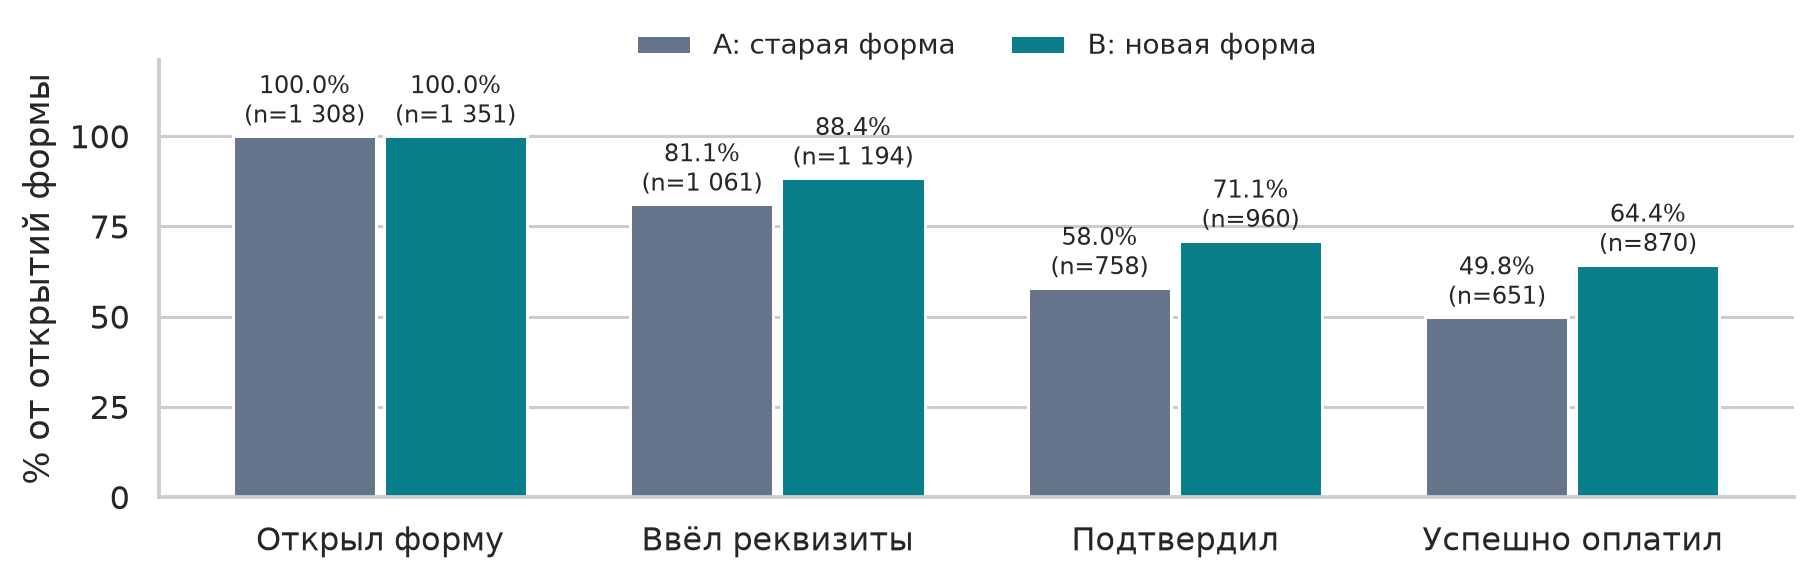

In [5]:
funnel_counts = clean.groupby('group')[STEPS].count().reindex(GROUPS)
funnel_rates = funnel_counts.div(funnel_counts['step1_opened'], axis=0)
transitions = pd.DataFrame(index=GROUPS)
for previous, current, label in zip(STEPS[:-1], STEPS[1:], ['1→2','2→3','3→4']):
    transitions[label] = funnel_counts[current] / funnel_counts[previous]
transitions['1→4'] = funnel_rates['step4_success']
summary = clients.groupby('group').agg(
    assigned=('user_id', 'size'), opened_users=('opened', lambda s: int(s.gt(0).sum())),
    successful_users=('successes', lambda s: int(s.gt(0).sum())),
    attempts=('opened', 'sum'), successes=('successes', 'sum')).reindex(GROUPS)
summary['attempt_cr'] = summary['successes']/summary['attempts']
summary['user_cr'] = summary['successful_users']/summary['opened_users']
delta = float(summary.loc['B','attempt_cr']-summary.loc['A','attempt_cr'])
relative_lift = float(summary.loc['B','attempt_cr']/summary.loc['A','attempt_cr']-1)
display(summary, funnel_counts, transitions)
print(f'Разница B−A: {delta*100:+.4f} п.п.; относительное изменение: {relative_lift*100:+.4f}%.')

stage_labels = ['Открыл форму', 'Ввёл реквизиты', 'Подтвердил', 'Успешно оплатил']
fig, ax = plt.subplots(figsize=(8.4, 2.8))
x = np.arange(4)
for group, offset in [('A',-.19),('B',.19)]:
    values = funnel_rates.loc[group].to_numpy()*100
    bars = ax.bar(x+offset, values, width=.36, color=COLORS[group],
                  label=f'{group}: ' + ('старая форма' if group=='A' else 'новая форма'))
    for j, bar in enumerate(bars):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+1.5,
                 f'{values[j]:.1f}%\n(n={int(funnel_counts.loc[group].iloc[j]):,})'.replace(',', ' '),
                 ha='center', va='bottom', fontsize=8)
ax.set_xticks(x, stage_labels)
ax.set(ylim=(0,121), ylabel='% от открытий формы')
ax.set_yticks([0,25,50,75,100])
ax.legend(loc='upper center', bbox_to_anchor=(.5,1.12), ncols=2, frameon=False, fontsize=9)
ax.grid(axis='x', visible=False)
fig.tight_layout()
funnel_path = WORK_DIR / 'funnel.png'
fig.savefig(funnel_path, dpi=220)
plt.close(fig)
from IPython.display import Image as NotebookImage
display(NotebookImage(filename=str(funnel_path)))

## 5. Статистический вывод с единицей рандомизации «клиент»
Для клиента $i$ сохраняем пару $(s_i,n_i)$: число успехов и открытий.
Метрика группы — $\sum_i s_i/\sum_i n_i$, а не среднее индивидуальных конверсий.
Клиенты без попыток имеют $(0,0)$ и остаются в таблице назначений.

- **95% ДИ**: percentile cluster bootstrap, 20 000 повторов. В каждой группе
  пересэмплируются клиенты с возвращением; все попытки клиента перемещаются вместе.
- **p-value**: двусторонний randomization/permutation test, 20 000 перестановок
  групп между клиентами без изменения размеров групп. Статистика — разница конверсий B−A.
  Нулевая гипотеза для перестановочного теста: назначение формы не влияет на результаты
  клиентов (sharp null); для продуктового вывода оценивается разница конверсий.
  Монте-Карло оценка $p=(1+\#\{|\Delta^*|\geq|\Delta_{obs}|\})/(20\,000+1)$.
- Уровень значимости — 0,05; bootstrap seed=42, permutation seed=43.

Условия: независимые клиенты, случайное назначение при фиксированных размерах групп,
нет существенного взаимовлияния между клиентами. При наличии реальной стратификации
назначений перестановки следовало бы делать внутри страт; такой информации в кейсе нет.
Обычный z-тест на строках платежей не используется. Основная проверка одна;
устройства и другие разрезы ниже — описательная диагностика без отбора «значимых» сегментов.

In [6]:
def cluster_inference(client_table, repeats=N_RESAMPLES, seed=SEED):
    arrays = {g: client_table.loc[client_table['group'].eq(g),
                                 ['successes', 'opened']].to_numpy(dtype=float) for g in GROUPS}
    rates = {g: arrays[g][:,0].sum()/arrays[g][:,1].sum() for g in GROUPS}
    observed = rates['B']-rates['A']
    rng = np.random.default_rng(seed)
    bootstrap_rates = {}
    for g in GROUPS:
        a = arrays[g]
        samples = np.empty(repeats)
        for start in range(0, repeats, 250):
            size = min(250, repeats-start)
            idx = rng.integers(0, len(a), size=(size,len(a)))
            totals = a[idx].sum(axis=1)
            assert (totals[:,1]>0).all()
            samples[start:start+size] = totals[:,0]/totals[:,1]
        bootstrap_rates[g] = samples
    bootstrap_delta = bootstrap_rates['B']-bootstrap_rates['A']
    ci_low, ci_high = np.quantile(bootstrap_delta, [0.025,0.975])

    all_clients = np.vstack([arrays['A'], arrays['B']])
    n_a = len(arrays['A'])
    totals = all_clients.sum(axis=0)
    rng_permutation = np.random.default_rng(seed+1)
    null_delta = np.empty(repeats)
    for j in range(repeats):
        selected_a = rng_permutation.permutation(len(all_clients))[:n_a]
        a_sum = all_clients[selected_a].sum(axis=0)
        b_sum = totals-a_sum
        assert min(a_sum[1],b_sum[1])>0
        null_delta[j] = b_sum[0]/b_sum[1]-a_sum[0]/a_sum[1]
    extreme = int((np.abs(null_delta)>=abs(observed)-1e-14).sum())
    p_value = (extreme+1)/(repeats+1)
    result = dict(cr_a=float(rates['A']), cr_b=float(rates['B']),
                  delta=float(observed), relative_lift=float(rates['B']/rates['A']-1),
                  ci_low=float(ci_low), ci_high=float(ci_high), p_value=float(p_value),
                  extreme=extreme, repeats=repeats)
    return result, bootstrap_delta, null_delta

inference, bootstrap_delta, null_delta = cluster_inference(clients)
sensitivity_rows = []
datasets = {'Основной: исключить платёж': (clean, clients)}
for label, policy in [('Исключить клиента', 'exclude_client'),
                      ('Группа из справочника', 'restore_group')]:
    datasets[label] = make_dataset(policy)
for label, (payment_data, client_data) in datasets.items():
    result = inference if label.startswith('Основной') else cluster_inference(client_data)[0]
    sensitivity_rows.append({'scenario':label, **result,
                              'users':len(client_data), 'payments':len(payment_data)})
sensitivity = pd.DataFrame(sensitivity_rows).set_index('scenario')
display(sensitivity[['cr_a','cr_b','delta','ci_low','ci_high','p_value','users','payments']])
print('Основной расчёт:', json.dumps(inference, ensure_ascii=False, indent=2))

def decision(r):
    if r['ci_low']>0 and r['p_value']<ALPHA:
        return 'positive'
    if r['ci_high']<0 and r['p_value']<ALPHA:
        return 'negative'
    return 'uncertain'

statuses = [decision(row) for _, row in sensitivity.iterrows()]
robust = len(set(statuses))==1
if decision(inference)=='positive' and robust:
    recommendation = 'Рекомендую поэтапное расширение новой формы'
    rationale = 'Рост конверсии статистически подтверждён и устойчив к обработке конфликта групп.'
elif decision(inference)=='negative' and robust:
    recommendation = 'Не рекомендую раскатку новой формы'
    rationale = 'Снижение конверсии статистически подтверждено и устойчиво к очистке.'
else:
    recommendation = 'Не рекомендую запуск на всех пользователей'
    rationale = 'Положительный эффект не подтверждён достаточно убедительно либо вывод зависит от очистки.'
display(Markdown('**'+recommendation+'.** '+rationale))

,cr_a,cr_b,delta,ci_low,ci_high,p_value,users,payments
scenario,,,,,,,,
Основной: исключить платёж,0.4977,0.6440,0.1463,0.1096,0.1828,0.0000,1503,2659
Исключить клиента,0.4981,0.6440,0.1459,0.1090,0.1828,0.0000,1502,2658
Группа из справочника,0.4981,0.6440,0.1459,0.1092,0.1825,0.0000,1503,2660


Основной расчёт: {
  "cr_a": 0.49770642201834864,
  "cr_b": 0.6439674315321984,
  "delta": 0.14626100951384974,
  "relative_lift": 0.29387004676515427,
  "ci_low": 0.1096384897962047,
  "ci_high": 0.18283571352346736,
  "p_value": 4.999750012499375e-05,
  "extreme": 0,
  "repeats": 20000
}


**Рекомендую поэтапное расширение новой формы.** Рост конверсии статистически подтверждён и устойчив к обработке конфликта групп.

## 6. Разрез по устройствам и дополнительные метрики
Разрез описательный: он помогает обнаружить возможный неоднородный эффект, но не
даёт отдельного основания для запуска. p-value по сегментам не вычисляем.
Для количественной рекомендации о сегменте потребовалась бы заранее заданная
гипотеза и отдельная проверка взаимодействия или эксперимент.

attempts  successes  users     cr
device_type group                                   
android     A           714        349    407 0.4888
            B           666        425    369 0.6381
ios         A           594        302    344 0.5084
            B           685        445    381 0.6496

group,A,B,delta_pp
device_type,,,
android,0.4888,0.6381,14.9343
ios,0.5084,0.6496,14.1218


Пользовательская конверсия: A=65.65%, B=80.40%; разница +14.75 п.п.
Это сравнение описательное, без дополнительного утверждения о значимости.


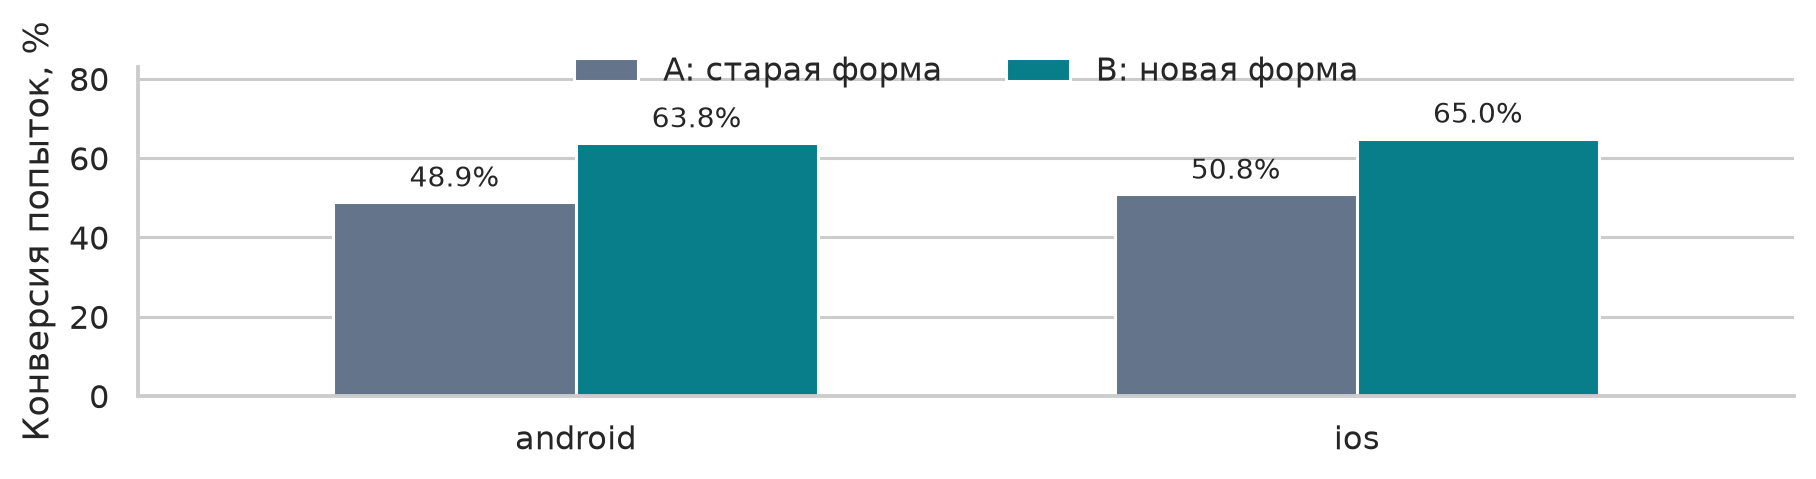

In [7]:
device_metrics = clean.groupby(['device_type','group']).agg(
    attempts=('payment_id','size'), successes=('success','sum'), users=('user_id','nunique'))
device_metrics['cr'] = device_metrics['successes']/device_metrics['attempts']
device_pivot = device_metrics['cr'].unstack('group').reindex(columns=GROUPS)
device_pivot['delta_pp'] = (device_pivot['B']-device_pivot['A'])*100
display(device_metrics, device_pivot)
user_delta_pp = float((summary.loc['B','user_cr']-summary.loc['A','user_cr'])*100)
print(f'Пользовательская конверсия: A={summary.loc["A","user_cr"]:.2%}, '
      f'B={summary.loc["B","user_cr"]:.2%}; разница {user_delta_pp:+.2f} п.п.')
print('Это сравнение описательное, без дополнительного утверждения о значимости.')

fig, ax = plt.subplots(figsize=(8.4, 2.25))
device_pivot[GROUPS].mul(100).plot.bar(
    ax=ax, color=[COLORS[g] for g in GROUPS], rot=0, width=.62)
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3, fontsize=9)
ax.set(ylabel='Конверсия попыток, %', xlabel='', ylim=(0,83))
ax.legend(['A: старая форма','B: новая форма'], frameon=False,
          loc='upper center', bbox_to_anchor=(.5,1.12), ncols=2)
ax.grid(axis='x',visible=False)
fig.tight_layout()
device_path = WORK_DIR/'devices.png'
fig.savefig(device_path,dpi=220)
plt.close(fig)
display(NotebookImage(filename=str(device_path)))


## 7. Дополнительные проверки и продуктовая интерпретация
Эти проверки не подменяют основную метрику и не используются для выбора
«самого значимого» результата.

1. **Одинаковый состав устройств.** Конверсии A/B перевзвешиваются на общие доли
   Android/iOS среди всех корректных попыток: $CR_g^{std}=\sum_d w_d CR_{g,d}$.
   Это описательная проверка чувствительности к составу, а не новый основной тест.
2. **Клиенты.** Проверяем долю клиентов хотя бы с одной оплатой среди открывавших
   и среди всех назначенных клиентов (дополнительная ITT-метрика).
3. **Первая попытка.** Берём первое по времени открытие каждого клиента, чтобы
   посмотреть, сохраняется ли направление эффекта без веса повторных попыток.
4. **Дельта-метод.** Независимая аналитическая проверка bootstrap-интервала.
   Для группы: $r=\sum s_i/\sum n_i$,
   $\widehat{Var}(r)=Var(s_i-rn_i)/(N\bar{n}^{2})$.
   Пользователи, а не платежи, являются независимыми наблюдениями.

Переходы воронки сравниваются описательно: состав дошедших до промежуточного
шага зависит от варианта. Поэтому максимум прироста условной конверсии
не доказывает, какой экран причинно объясняет общий эффект.

In [8]:
# Единые веса устройств для конверсий попыток обеих групп.
device_weights = clean.groupby('device_type').size()/len(clean)
standardized = {g: float(sum(device_weights[d]*device_metrics.loc[(d,g),'cr']
                            for d in device_weights.index)) for g in GROUPS}
standardized_delta = standardized['B']-standardized['A']

# Отдельная бинарная метрика по всем назначенным клиентам, включая (0,0).
itt = clients.assign(converted=clients['successes'].gt(0)).groupby('group')['converted'].agg(['size','sum','mean'])
first_attempts = clean.sort_values(['step1_opened','payment_id']).drop_duplicates('user_id')
first_summary = first_attempts.groupby('group')['success'].agg(['size','sum','mean']).reindex(GROUPS)

# Дельта-метод для отношения сумм с дисперсией на уровне клиента.
ratio_variances = {}
for g in GROUPS:
    t = clients.loc[clients['group'].eq(g)]
    r = t['successes'].sum()/t['opened'].sum()
    residual = t['successes']-r*t['opened']
    ratio_variances[g] = residual.var(ddof=1)/(len(t)*t['opened'].mean()**2)
delta_se = float(np.sqrt(sum(ratio_variances.values())))
normal_critical = stats.norm.ppf(1-ALPHA/2)
analytic_ci = (delta-normal_critical*delta_se, delta+normal_critical*delta_se)
analytic_p = float(2*stats.norm.sf(abs(delta/delta_se)))

stage_delta_pp = (transitions.loc['B']-transitions.loc['A'])*100
extra_per_1000 = inference['delta']*1000
extra_ci = (inference['ci_low']*1000, inference['ci_high']*1000)
robustness = pd.DataFrame([
    ['Конверсия попыток', summary.loc['A','attempt_cr'],summary.loc['B','attempt_cr']],
    ['Одинаковый состав устройств',standardized['A'],standardized['B']],
    ['Клиенты с ≥1 оплатой среди открывавших',summary.loc['A','user_cr'],summary.loc['B','user_cr']],
    ['Успех первой попытки клиента',first_summary.loc['A','mean'],first_summary.loc['B','mean']],
],columns=['Проверка','A','B']).set_index('Проверка')
robustness['Разница, п.п.'] = (robustness['B']-robustness['A'])*100
display(robustness)
display(itt.rename(columns={'size':'Назначено','sum':'С оплатой','mean':'Доля'}))
display(first_summary)
display(pd.DataFrame({'Метод':['Кластерный bootstrap','Дельта-метод'],
                      'Нижняя граница, п.п.':[inference['ci_low']*100,analytic_ci[0]*100],
                      'Верхняя граница, п.п.':[inference['ci_high']*100,analytic_ci[1]*100]}))
print(f'Аналитическая проверка: SE={delta_se*100:.4f} п.п., p={analytic_p:.6g}.')
print(f'При сохранении эффекта: {extra_per_1000:.1f} дополнительных успешных попыток '
      f'на 1000 открытий, 95% ДИ [{extra_ci[0]:.1f}; {extra_ci[1]:.1f}].')
print('Переходы воронки, разница B−A в п.п.:')
display(stage_delta_pp)
print('Медиана времени среди успешных оплат:',
      durations.groupby('group')['minutes'].median().to_dict(), 'мин.')
print('Времена только успешных оплат не дают причинной оценки ускорения формы.')

,A,B,"Разница, п.п."
Проверка,,,
Конверсия попыток,0.4977,0.6440,14.6261
Одинаковый состав устройств,0.4982,0.6437,14.5434
Клиенты с ≥1 оплатой среди открывавших,0.6565,0.8040,14.7542
Успех первой попытки клиента,0.5073,0.6573,15.0010


,Назначено,С оплатой,Доля
group,,,
A,752,493,0.6556
B,751,603,0.8029


,size,sum,mean
group,,,
A,751,381,0.5073
B,750,493,0.6573


,Метод,"Нижняя граница, п.п.","Верхняя граница, п.п."
0,Кластерный bootstrap,10.9638,18.2836
1,Дельта-метод,10.9202,18.3320


Аналитическая проверка: SE=1.8908 п.п., p=1.03069e-14.
При сохранении эффекта: 146.3 дополнительных успешных попыток на 1000 открытий, 95% ДИ [109.6; 182.8].
Переходы воронки, разница B−A в п.п.:


1→2    7.2628
2→3    8.9600
3→4    4.7411
1→4   14.6261
dtype: float64

Медиана времени среди успешных оплат: {'A': 12.0, 'B': 12.0} мин.
Времена только успешных оплат не дают причинной оценки ускорения формы.


## 8. Проверки расчётов и ограничения
Проверяем сохранение количества платежей при JOIN, согласование этапов воронки,
сводок и пользовательских счётчиков; исходный Excel должен остаться неизменным.
Не используем среднее индивидуальных конверсий вместо отношения сумм.

Ограничения: соответствие A/B и ожидаемый сплит приняты как допущения. Успехи
наблюдаются в пределах выгрузки за апрель: более поздние завершения и одинаковые
окна наблюдения после последней попытки не проверяются. Без информации о назначении
и экспозиции нельзя полностью проверить проведение эксперимента. Нет финансовых
показателей, ошибок реквизитов, обращений в поддержку и данных о повторных списаниях.
Статистическая значимость не означает автоматически коммерческую выгоду.

In [9]:
checks = {}
checks['JOIN не размножает платежи'] = len(joined)==len(raw_payments)
checks['Одна строка на назначенного клиента'] = clients['user_id'].is_unique
checks['Все группы определены'] = clients['group'].isin(GROUPS).all()
checks['Успехов не больше открытий у каждого клиента'] = clients['successes'].le(clients['opened']).all()
checks['Счётчики клиентов согласуются с платежами'] = (
    clients['opened'].sum()==len(clean) and clients['successes'].sum()==clean['success'].sum())
checks['Конверсия в допустимых пределах'] = summary[['attempt_cr','user_cr']].ge(0).all().all() and summary[['attempt_cr','user_cr']].le(1).all().all()
checks['Воронка невозрастающая'] = (np.diff(funnel_counts.to_numpy(), axis=1)<=0).all()
checks['Сводка по группам согласуется с воронкой'] = (
    summary['attempts'].equals(funnel_counts['step1_opened']) and
    summary['successes'].equals(funnel_counts['step4_success']))
checks['Исключения согласуются с масками очистки'] = len(raw_payments)-len(clean)==int((~basic_valid | group_conflict).sum())
checks['Дополнительные политики согласованы'] = (
    len(datasets['Группа из справочника'][0])==int(basic_valid.sum()) and
    not datasets['Исключить клиента'][1]['user_id'].isin(conflict_users).any())
checks['ДИ и p-value допустимы'] = inference['ci_low']<inference['ci_high'] and 0<inference['p_value']<=1
checks['Исходный Excel не изменён'] = hashlib.sha256(SOURCE_XLSX.read_bytes()).hexdigest()==source_sha256
display(pd.DataFrame({'Проверка':list(checks), 'Результат':['OK' if v else 'ОШИБКА' for v in checks.values()]}))
assert all(checks.values()), {k:v for k,v in checks.items() if not v}

result_payload = {'source_name':FILE_NAME, 'source_sha256':source_sha256, 'versions':versions,
                  'summary':summary.reset_index().to_dict('records'), 'inference':inference,
                  'sensitivity':sensitivity.reset_index().to_dict('records'),
                  'srm_p':float(srm_p), 'age_smd':float(age_smd), 'recommendation':recommendation,
                  'checks':{k:bool(v) for k,v in checks.items()}}
(WORK_DIR/'results.json').write_text(json.dumps(result_payload, ensure_ascii=False, indent=2), encoding='utf-8')

,Проверка,Результат
0,JOIN не размножает платежи,OK
1,Одна строка на назначенного клиента,OK
2,Все группы определены,OK
3,Успехов не больше открытий у каждого клиента,OK
4,Счётчики клиентов согласуются с платежами,OK
5,Конверсия в допустимых пределах,OK
6,Воронка невозрастающая,OK
7,Сводка по группам согласуется с воронкой,OK
8,Исключения согласуются с масками очистки,OK
9,Дополнительные политики согласованы,OK


3192

## 9. Таблицы для краткого отчёта
Сначала формируем pandas DataFrame, затем выводим его как изображение таблицы.
Это реальные результаты ячеек notebook. PDF использует те же PNG, без ручного
переноса или перерисовки значений. Дополнительные таблицы выше остаются доступными
в обычном выводе pandas и не перегружают двухстраничный отчёт.

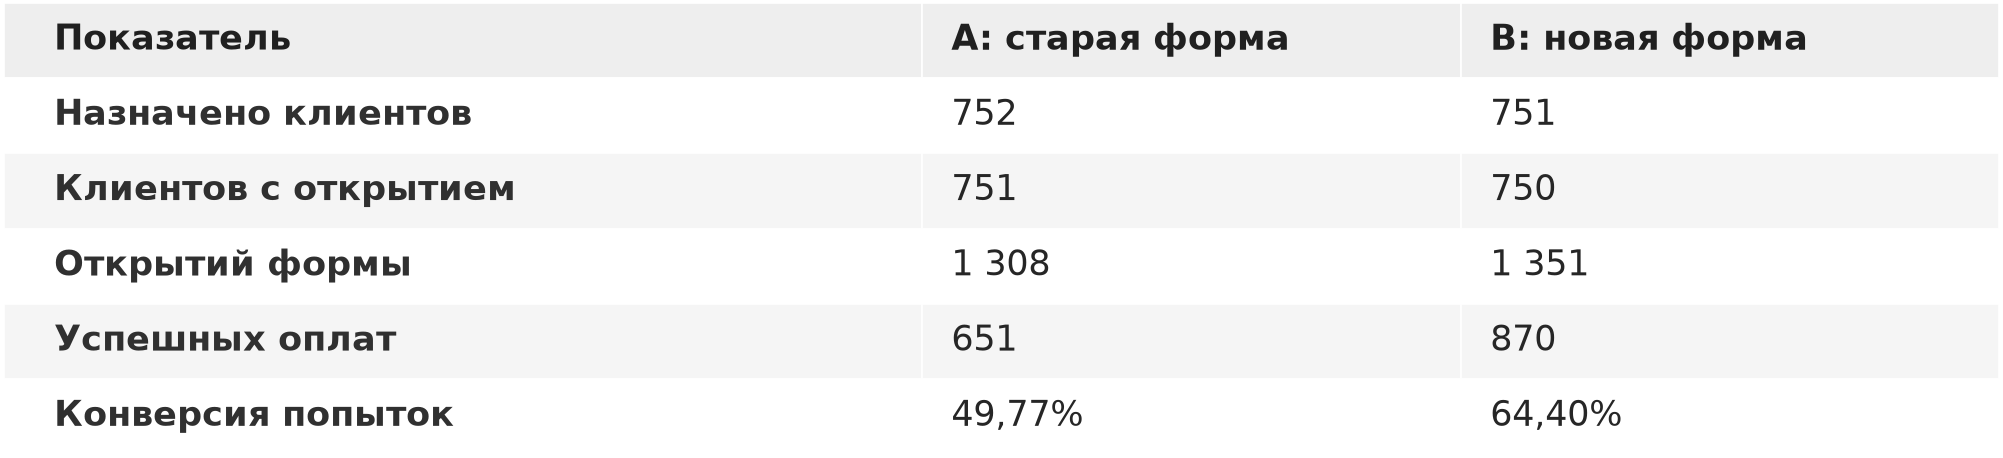

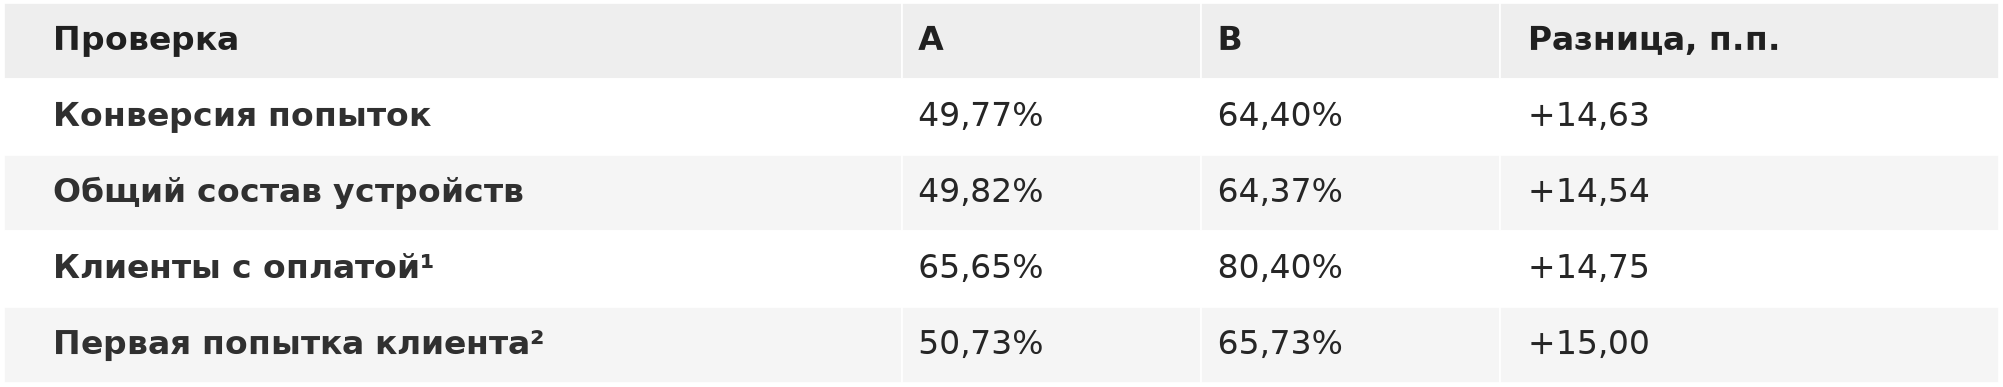

4192

In [10]:
from decimal import Decimal, ROUND_HALF_UP
def ru_percent(value):
    rounded=Decimal(str(value*100)).quantize(Decimal('0.01'),rounding=ROUND_HALF_UP)
    return (str(rounded)+'%').replace('.',',')
def ru_number(value):
    return f'{int(value):,}'.replace(',',' ')
def ru_delta(value):
    return f'{value*100:+.2f}'.replace('.',',')

def show_dataframe_image(frame,path,width=8.4,column_widths=None,font_size=10):
    # Стиль, близкий к обычному выводу pandas в Jupyter: белый фон, индекс слева,
    # полужирная строка заголовков и чередующиеся светлые строки.
    view = frame.reset_index()
    row_count = len(view)+1
    height = .31*row_count+.10
    fig,ax = plt.subplots(figsize=(width,height))
    ax.axis('off')
    table=ax.table(cellText=view.astype(str).values,colLabels=view.columns,
                   colWidths=column_widths,cellLoc='left',colLoc='left',bbox=[0,0,1,1])
    table.auto_set_font_size(False)
    table.set_fontsize(font_size)
    for (row,col),cell in table.get_celld().items():
        cell.set_edgecolor('white')
        cell.set_linewidth(.5)
        cell.PAD=.055
        if row==0:
            cell.set_facecolor('#eeeeee')
            cell.set_text_props(weight='bold',color='#202020')
        else:
            cell.set_facecolor('#f5f5f5' if row%2==0 else 'white')
            if col==0:cell.set_text_props(weight='bold',color='#303030')
    fig.subplots_adjust(left=.005,right=.995,top=.98,bottom=.02)
    fig.savefig(path,dpi=240,pad_inches=.015)
    plt.close(fig)
    display(NotebookImage(filename=str(path)))

metric_view=pd.DataFrame({
    'A: старая форма':[ru_number(summary.loc['A',k]) for k in ['assigned','opened_users','attempts','successes']]+[ru_percent(summary.loc['A','attempt_cr'])],
    'B: новая форма':[ru_number(summary.loc['B',k]) for k in ['assigned','opened_users','attempts','successes']]+[ru_percent(summary.loc['B','attempt_cr'])],
},index=['Назначено клиентов','Клиентов с открытием','Открытий формы','Успешных оплат','Конверсия попыток'])
metric_view.index.name='Показатель'
metric_table_path=WORK_DIR/'metrics_table.png'
show_dataframe_image(metric_view,metric_table_path,column_widths=[.46,.27,.27],font_size=10.5)

robustness_view=robustness.copy()
for g in GROUPS:robustness_view[g]=robustness_view[g].map(ru_percent)
robustness_view['Разница, п.п.']=robustness_view['Разница, п.п.'].map(lambda x:f'{x:+.2f}'.replace('.',','))
robustness_view.index=['Конверсия попыток','Общий состав устройств','Клиенты с оплатой¹','Первая попытка клиента²']
robustness_view.index.name='Проверка'
robustness_table_path=WORK_DIR/'robustness_table.png'
show_dataframe_image(robustness_view,robustness_table_path,
                     column_widths=[.45,.15,.15,.25],font_size=10)

assert metric_view.loc['Открытий формы','A: старая форма']==ru_number(funnel_counts.loc['A','step1_opened'])
assert np.isclose(standardized_delta,standardized['B']-standardized['A'])
assert all(path.is_file() for path in [funnel_path,device_path,metric_table_path,robustness_table_path])
result_payload['additional_checks']={
    'device_standardized_cr':standardized,'device_standardized_delta':float(standardized_delta),
    'first_attempts':first_summary.reset_index().to_dict('records'),
    'itt':itt.reset_index().to_dict('records'),
    'delta_method_ci':list(map(float,analytic_ci)),'delta_method_p':analytic_p,
    'extra_successes_per_1000':float(extra_per_1000),
    'report_images':[p.name for p in [funnel_path,device_path,metric_table_path,robustness_table_path]],
}
(WORK_DIR/'results.json').write_text(json.dumps(result_payload,ensure_ascii=False,indent=2),encoding='utf-8')

## 10. Итоговый PDF
Две страницы для продуктовой команды. Основной вывод, изображения таблиц и
графиков подставляются из рассчитанных переменных. Ссылка на репозиторий кликабельна.
Промежуточные изображения сохраняются только в игнорируемой папке `.artifacts/`.

In [11]:
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Image, PageBreak, Table, TableStyle
from reportlab.lib import colors
from reportlab.lib.styles import ParagraphStyle
from reportlab.lib.pagesizes import A4
from reportlab.lib.units import mm
from reportlab.pdfbase import pdfmetrics
from reportlab.pdfbase.ttfonts import TTFont
from pypdf import PdfReader
from PIL import Image as PILImage

for family,weight,name in [('DejaVu Sans','normal','CaseSans'),('DejaVu Sans','bold','CaseSansBold')]:
    font=font_manager.findfont(font_manager.FontProperties(family=family,weight=weight))
    pdfmetrics.registerFont(TTFont(name,font))
pdfmetrics.registerFontFamily('CaseSans',normal='CaseSans',bold='CaseSansBold',italic='CaseSans',boldItalic='CaseSansBold')
INK=colors.HexColor('#202020');MUTED=colors.HexColor('#555555');ACCENT=colors.HexColor('#202020')
WIDTH=A4[0]-32*mm
styles={
 'title':ParagraphStyle('title',fontName='CaseSansBold',fontSize=19,leading=24,textColor=INK,spaceAfter=4),
 'sub':ParagraphStyle('sub',fontName='CaseSans',fontSize=8.8,leading=12,textColor=MUTED,spaceAfter=7),
 'h':ParagraphStyle('h',fontName='CaseSansBold',fontSize=10.8,leading=14,textColor=INK,spaceBefore=7,spaceAfter=4),
 'body':ParagraphStyle('body',fontName='CaseSans',fontSize=9.0,leading=12.4,textColor=INK,spaceAfter=5),
 'small':ParagraphStyle('small',fontName='CaseSans',fontSize=7.9,leading=10.5,textColor=MUTED,spaceAfter=4),
 'verdict':ParagraphStyle('verdict',fontName='CaseSansBold',fontSize=11.5,leading=15.5,textColor=ACCENT,spaceAfter=6),
 'box_title':ParagraphStyle('box_title',fontName='CaseSansBold',fontSize=10.5,leading=14,textColor=INK,spaceAfter=4),
 'box_number':ParagraphStyle('box_number',fontName='CaseSansBold',fontSize=17,leading=22,textColor=INK,spaceAfter=5),
}
def P(text,style='body'):return Paragraph(text,styles[style])
def figure(path,width=WIDTH):
    with PILImage.open(path) as img:w,h=img.size
    return Image(str(path),width=width,height=width*h/w)
def ci_text(lo,hi):return f'[{ru_delta(lo)}; {ru_delta(hi)}]'

result_box=Table([[[
    P('Итоговые результаты','box_title'),
    P(f'{ru_percent(inference["cr_a"])} → {ru_percent(inference["cr_b"])}','box_number'),
    P(f'Конверсия в успешную оплату выросла на <b>{ru_delta(delta)} п.п.</b> '
      f'({ru_delta(relative_lift)}% относительно A). '
      f'95% ДИ: <b>{ci_text(inference["ci_low"],inference["ci_high"])} п.п.</b>; p &lt; 0,001.'),
    P('<b>Рекомендация: внедрять новую форму, расширяя охват постепенно.</b>'),
]]],colWidths=[WIDTH])
result_box.setStyle(TableStyle([
    ('BACKGROUND',(0,0),(-1,-1),colors.HexColor('#f4f4f4')),
    ('BOX',(0,0),(-1,-1),.6,colors.HexColor('#bdbdbd')),
    ('LEFTPADDING',(0,0),(-1,-1),12),('RIGHTPADDING',(0,0),(-1,-1),12),
    ('TOPPADDING',(0,0),(-1,-1),10),('BOTTOMPADDING',(0,0),(-1,-1),6),
]))
story=[P('A/B-тест формы оплаты ЖКХ','title'),
       P('С 1 по 30 апреля 2024 года сравнивали две формы оплаты. '
         'Проверял, помогает ли упрощённое заполнение реквизитов чаще доводить оплату до конца.'),
       Spacer(1,5),result_box,Spacer(1,7),
       P(f'При таком эффекте на каждые 1 000 открытий приходится примерно '
         f'<b>{extra_per_1000:.0f} дополнительных успешных оплат</b> '
         f'(95% ДИ: {extra_ci[0]:.0f}-{extra_ci[1]:.0f}). '
         'Оценка относится к сопоставимому трафику.'),
       P('Группы и метрика','h'),
       P('Считал долю успешных оплат от всех открытий формы. '
         'Каждую попытку учитывал отдельно; зависимость попыток одного клиента учёл в статистической проверке.','small'),
       figure(metric_table_path),
       P('Где меняется воронка','h'),
       figure(funnel_path),
       P('Высота столбца - доля от открытий формы в группе; n - число попыток на шаге.','small'),
       P(f'Переходы A → B: открытие → реквизиты <b>{ru_percent(transitions.loc["A","1→2"])} → '
         f'{ru_percent(transitions.loc["B","1→2"])}</b>; реквизиты → подтверждение '
         f'<b>{ru_percent(transitions.loc["A","2→3"])} → {ru_percent(transitions.loc["B","2→3"])}</b>; '
         f'подтверждение → успех <b>{ru_percent(transitions.loc["A","3→4"])} → '
         f'{ru_percent(transitions.loc["B","3→4"])}</b>.'),
       P('Что исключил из данных','h'),
       P(f'Из {ru_number(len(raw_users))} пользователей и {ru_number(len(raw_payments))} попыток '
         'исключены один клиент без группы и два платежа: без user_id и с конфликтом групп. '
         'Два некорректных возраста заменены пропусками; пустой город - отдельная категория. '
         f'Итог: <b>{ru_number(len(clients))} назначенных клиента и {ru_number(len(clean))} попыток</b>. '
         'Дубликатов ключей, нарушений порядка шагов и открытий вне апреля не найдено.'),
       PageBreak(),
       P('Проверки результата','title'),
       P('Как сравнивал группы','h'),
       P(f'У {int(clients["opened"].gt(1).sum())} клиентов несколько корректных попыток. '
         'Поэтому платежи одного клиента не считаются независимыми: для 95% ДИ использован '
         '<b>кластерный bootstrap по клиентам</b>, для p-value - <b>перестановка групп между клиентами</b> '
         'с сохранением их размеров. По 20 000 повторов, α=0,05. '
         'В каждом повторе метрика остаётся отношением сумм успехов и открытий.'),
       P(f'Сплит назначений {assigned["A"]}/{assigned["B"]}: при ожидаемом 50/50 '
         f'SRM p={str(round(srm_p,3)).replace(".",",")}. Средний возраст '
         f'{format(age_summary.loc["A","mean"],".2f").replace(".",",")}/'
         f'{format(age_summary.loc["B","mean"],".2f").replace(".",",")} года; '
         'близость этих характеристик сама по себе не доказывает корректность рандомизации.','small'),
       P('Меняется ли вывод при других расчётах','h'),
       figure(robustness_table_path),
       P('¹ Доля клиентов с хотя бы одной оплатой среди открывавших форму. '
         '² Успешность первой по времени попытки каждого клиента. Это другие метрики; '
         'они показаны описательно и не заменяют основной тест.','small'),
       P(f'При общем составе Android/iOS эффект {ru_delta(standardized_delta)} п.п.: '
         'различие устройств не объясняет наблюдаемый рост. При двух альтернативных правилах '
         f'обработки конфликта групп основной эффект остаётся '
         f'{ru_delta(sensitivity.iloc[1]["delta"])} / {ru_delta(sensitivity.iloc[2]["delta"])} п.п., p &lt; 0,001. '
         f'Аналитическая проверка дельта-методом даёт близкий ДИ '
         f'{ci_text(analytic_ci[0],analytic_ci[1])} п.п.','small'),
       figure(device_path),
       P('Исследовательский разрез по устройствам; значимость внутри сегментов отдельно не проверялась.','small'),
       P('Что делать дальше','h'),
       P('Предлагаю постепенно увеличивать долю пользователей новой формы. '
         'При расширении следить за ошибками оплаты и реквизитов, повторными списаниями '
         'и обращениями в поддержку. Заранее согласовать, при каком ухудшении этих показателей остановить раскатку.'),
       P(f'Наибольший прирост условной конверсии - между реквизитами и подтверждением '
         f'({ru_delta(stage_delta_pp["2→3"]/100)} п.п.). '
         'Это направление дальнейшего исследования, а не доказанная причина общего эффекта: '
         'состав дошедших до шага может различаться. В файле нет выручки и данных об ошибках оплаты; '
         'завершения после апреля не видны.','small'),
       P('В описании не указано соответствие вариантов A/B. Для интерпретации результатов '
         'принял A за контроль, B за новую форму; перед внедрением это нужно подтвердить.','small'),
       P(f'<b>Расчёты:</b> <link href="{REPO_URL}" color="#245780">'
         'github.com/9ecolla/tbank-product-analytics-case</link>','body')]

def footer(canvas,doc):
    canvas.saveState();canvas.setFont('CaseSans',7.2);canvas.setFillColor(MUTED)
    canvas.drawRightString(A4[0]-16*mm,9*mm,str(doc.page));canvas.restoreState()
pdf=SimpleDocTemplate(str(PDF_PATH),pagesize=A4,leftMargin=16*mm,rightMargin=16*mm,
                      topMargin=13*mm,bottomMargin=15*mm,
                      title='A/B-тест формы оплаты ЖКХ',author='Руслан Ахметов')
pdf.build(story,onFirstPage=footer,onLaterPages=footer)
reader=PdfReader(PDF_PATH)
assert len(reader.pages)==2,f'Получилось {len(reader.pages)} страниц вместо двух'
links=[]
for page in reader.pages:
    for ref in page.get('/Annots',[]):
        action=ref.get_object().get('/A',{})
        if action.get('/URI'):links.append(str(action['/URI']))
assert REPO_URL in links,'В PDF отсутствует кликабельная ссылка на репозиторий'
assert hashlib.sha256(SOURCE_XLSX.read_bytes()).hexdigest()==source_sha256
print('Сформирован report.pdf: 2 страницы, 4 изображения из notebook, кликабельная ссылка на GitHub.')

Сформирован report.pdf: 2 страницы, 4 изображения из notebook, кликабельная ссылка на GitHub.
